# Dendrogram tryout

In [1]:
import os
os.chdir("D:/Projets_python/Pardon my French Project/PardonMyFrench")

In [2]:
#Can take up to 1 min
import score_utils as scoring
import comparing_and_showing as cs
import matplotlib.pyplot as plt
import pandas as pd
import chunking
import numpy as np
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import fcluster
from scipy.spatial.distance import squareform, pdist
from scipy.linalg import norm as normalize_l2
from scipy.spatial import distance_matrix as dm
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import squareform, pdist

from sklearn.metrics import fowlkes_mallows_score

from copy import deepcopy

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tomww\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
def create_dendrogram(distances, labels, title, ax=None, color_map=None, roots=None, show_labels=True, method="average"):
    X = distances

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 5))
        fig.patch.set_facecolor(cs.CREME)

    Z = cs.linkage(X, method=method)#, metric=metric)

    if roots is None:
        roots = [cs.get_root(l) for l in labels]
    
    cs.dendrogram(Z, labels=roots, ax=ax, leaf_rotation=90, leaf_font_size=8,
               link_color_func=lambda k: cs.BRIQUE)   # branches en rouge brique

    # Fond, titre, axes
    ax.set_facecolor(cs.CREME)
    ax.set_title(title, color=cs.BRIQUE, fontweight="bold")
    ax.tick_params(axis="y", colors=cs.BRIQUE)
    for spine in ax.spines.values():
        spine.set_color(cs.BRIQUE)

    # Étiquettes colorées par persona

    label_to_root = dict(zip(labels, roots))
    if color_map is None:
        color_map = cs.make_color_map(labels)

    for tick in ax.get_xmajorticklabels():
        root = tick.get_text()
        tick.set_color(color_map.get(root, cs.BRIQUE))

    if not show_labels :
        ax.set_xticklabels(['▬▬▬' for _ in labels])
    
    return ax

In [4]:
def den(d, l, ar, title, scorers) :

    if ar not in os.listdir("Figures") : 
        os.mkdir(f"Figures/{ar}")

    base_path = f"Figures/{ar}/{ar}_"
    
    if "BASELINE" in title :
        base_path += 'baseline_'

    for s in scorers : 
        create_dendrogram(d[s.name], l, f"{title}\nusing {s.description}")
        
        path = base_path+s.name+"_dendrogram.png"
        plt.savefig(path, bbox_inches='tight')
        plt.close()

    s = "non_sem_vec"
    desc = "Non Semantic Metrics Vector"
    create_dendrogram(d[s], l, f"{title}\nusing {desc}")
    
    path = base_path+s+"_dendrogram.png"
    plt.savefig(path, bbox_inches='tight')
    plt.close()

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def heatmap(X, xlabels=None, ylabels=None, cmap="viridis_r",
            title=None, annotate=True, fmt=".2f", cbar_label=None):
    X = np.asarray(X)
    n_rows, n_cols = X.shape  # ici 8 x 11

    # Labels par défaut : indices
    xlabels = xlabels if xlabels is not None else list(range(n_cols))
    ylabels = ylabels if ylabels is not None else list(range(n_rows))

    assert len(xlabels) == n_cols, f"xlabels doit avoir {n_cols} éléments"
    assert len(ylabels) == n_rows, f"ylabels doit avoir {n_rows} éléments"

    fig, ax = plt.subplots(figsize=(10, 6))
    im = ax.imshow(X, cmap=cmap, aspect="auto")

    # Labels personnalisés
    ax.set_xticks(np.arange(n_cols))
    ax.set_yticks(np.arange(n_rows))
    ax.set_xticklabels(xlabels, rotation=45, ha="right")
    ax.set_yticklabels(ylabels)

    # Valeurs dans les cases
    if annotate:
        seuil = (X.max() + X.min()) / 2
        for i in range(n_rows):
            for j in range(n_cols):
                ax.text(j, i, format(X[i, j], fmt), ha="center", va="center",
                        color="white" if X[i, j] > seuil else "black", fontsize=8)

    cbar = fig.colorbar(im, ax=ax)
    if cbar_label:
        cbar.set_label(cbar_label)
    if title:
        ax.set_title(title)

    fig.tight_layout()
    return fig, ax

In [6]:
from sklearn.metrics import adjusted_rand_score

import numpy as np
from sklearn import metrics

def purity_score(y_true, y_pred):
    # compute contingency matrix (also called confusion matrix)
    contingency_matrix = metrics.cluster.contingency_matrix(y_true, y_pred)
    # return purity
    return np.sum(np.amax(contingency_matrix, axis=0)) / np.sum(contingency_matrix)

In [7]:
def get_n_personas(a) : 
    return len(chunking.artist_folder_to_artist_df(f"Corpus/{a}/{a}_songs")["persona_id"].unique())

In [8]:
linkages = dict()
ids = dict()

In [9]:
import gc
gc.collect()
artistes = os.listdir("Corpus")
scorers = scoring.available_metrics



for a in artistes :
    print(a)
    path = f"Corpus/{a}/{a}_songs"
    db = cs.create_baseline(path)

    #Résultats NORMAUX
    d, l = cs.get_aggregated_results(path, scorers=scorers, verbose=False, n_sample=5)
    None_holder = den(d, l, a, f"Dendrogram of {a} data :", scorers)
    ids[f"{a}"] = l
    linkages[f"{a}"] = {s : linkage(d[s], method='average') for s in d}
    gc.collect()

    #Résultats BASELINE
    d, l = cs.get_aggregated_results("", scorers=scorers, verbose=False, optional_df=db, n_sample=5)
    None_holder = den(d, l, a, f"Dendrogram of BASELINE data for {a} :", scorers)
    ids[f"{a}_baseline"] = l
    linkages[f"{a}_baseline"] = {s : linkage(d[s], method='average') for s in d}
    gc.collect()


Beyonce
Eminem
KoolKeith
MacMiller
MFDOOM
TateMcRae
TwentyOnePilots
TylerTheCreator


In [10]:
ids_root = {k : list(map(lambda x : cs.get_root(x), ids[k])) for k in ids}
score_res = {a : dict() for a in artistes}
score_base = {a : dict() for a in artistes}


In [11]:
scoring_cluster = adjusted_rand_score
its_name = "ARI"
savepath = f"D:/Projets_python/Pardon my French Project/PardonMyFrench/FiguresGlobal/{its_name}/"

for a in artistes : 
    n_personas = get_n_personas(a)
    b = a+"_baseline"
    for s in linkages[a] :
        results = fcluster(linkages[a][s], t=n_personas, criterion="maxclust")
        baseline = fcluster(linkages[b][s], t=n_personas, criterion="maxclust")
        id_results = ids_root[a]
        id_baseline = ids_root[a+"_baseline"]
        score_res[a][s] = scoring_cluster(id_results, results)
        score_base[a][s] = scoring_cluster(id_baseline, baseline)

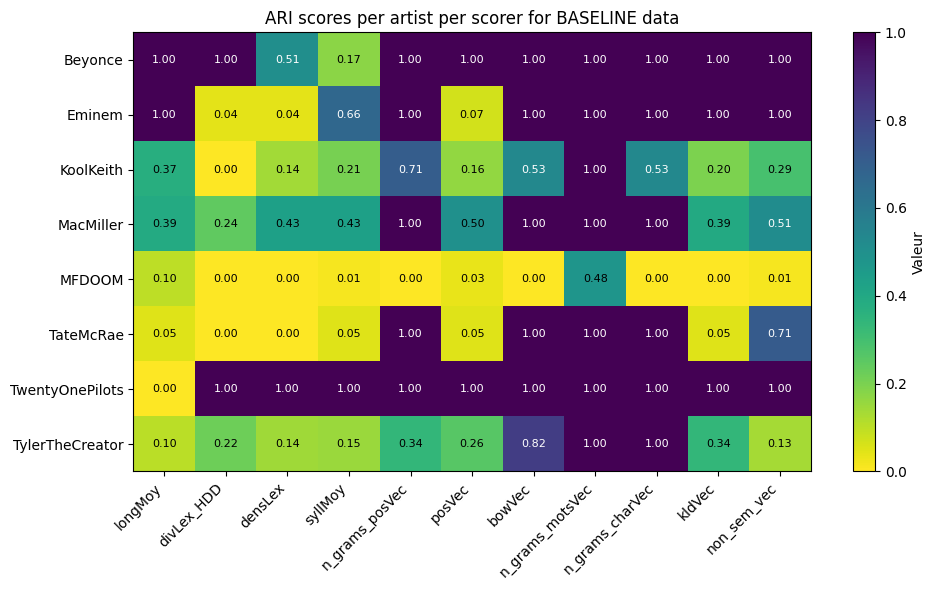

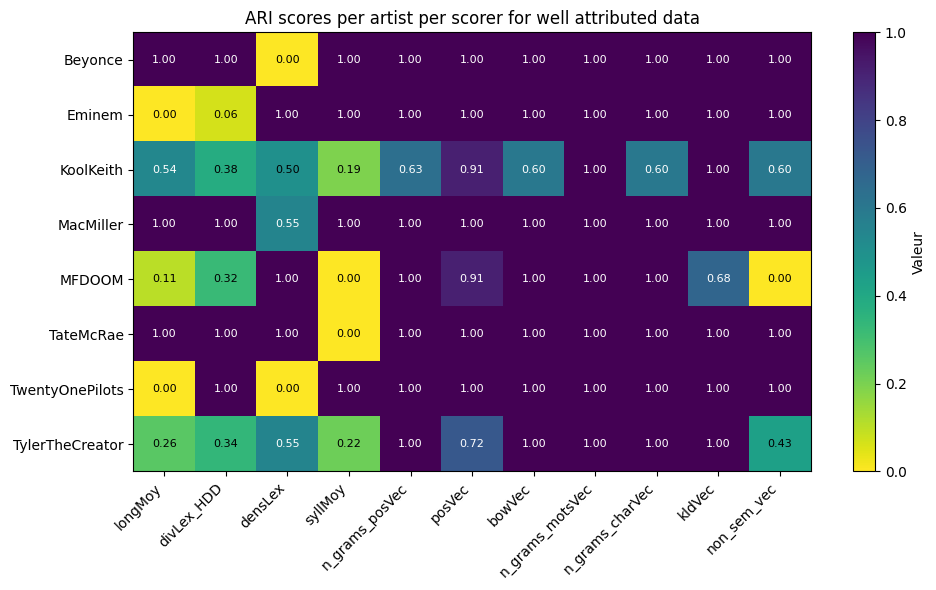

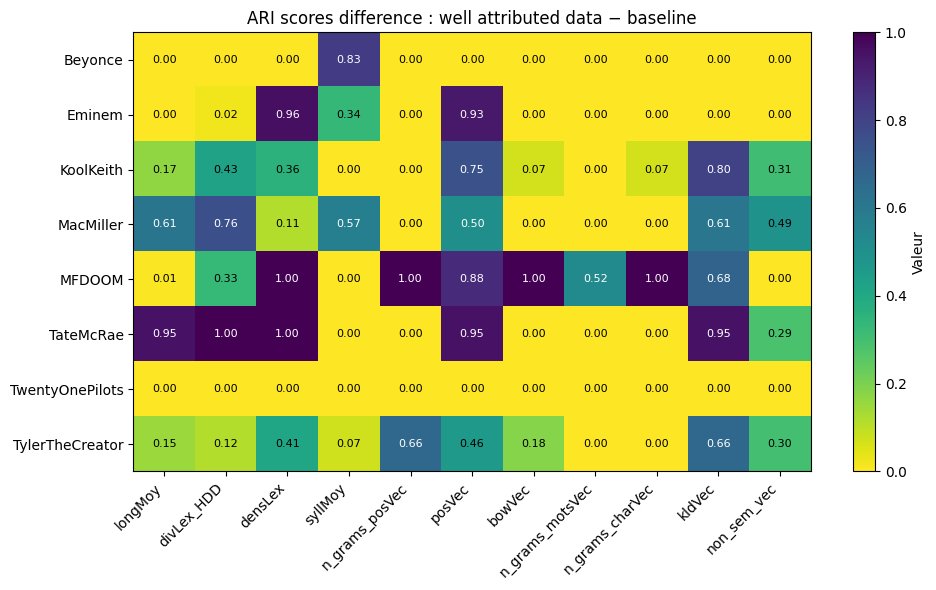

In [12]:
X = np.clip(np.array([[score_base[a][u] for u in score_base[a]] for a in score_base]), 0, 1)
xlabels = list(score_base[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes  # 8 labels en ordonnée
heatmap(X, xlabels=xlabels, ylabels=ylabels, title=f"{its_name} scores per artist per scorer for BASELINE data", cbar_label="Valeur")
plt.savefig(f"Baseline_{its_name}")

X = np.clip(np.array([[score_res[a][u] for u in score_res[a]] for a in score_res]), 0, 1)
xlabels = list(score_res[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes # 8 labels en ordonnée
heatmap(X, xlabels=xlabels, ylabels=ylabels, title=f"{its_name} scores per artist per scorer for well attributed data", cbar_label="Valeur")
plt.savefig(f"Normal_{its_name}")


X = np.clip(np.array([[score_res[a][u] - score_base[a][u] for u in score_base[a]] for a in score_res]), 0, 1)
xlabels = list(score_base[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes  # 8 labels en ordonnée
heatmap(X, xlabels=xlabels, ylabels=ylabels, title=f"{its_name} scores difference : well attributed data − baseline", cbar_label="Valeur")
plt.savefig(f"Difference_{its_name}")


In [13]:
scoring_cluster = purity_score
its_name = "Purity"
savepath = f"D:/Projets_python/Pardon my French Project/PardonMyFrench/FiguresGlobal/{its_name}/"
for a in artistes : 
    n_personas = get_n_personas(a)
    b = a+"_baseline"
    for s in linkages[a] :
        results = fcluster(linkages[a][s], t=n_personas, criterion="maxclust")
        baseline = fcluster(linkages[b][s], t=n_personas, criterion="maxclust")
        id_results = ids_root[a]
        id_baseline = ids_root[a+"_baseline"]
        score_res[a][s] = scoring_cluster(id_results, results)
        score_base[a][s] = scoring_cluster(id_baseline, baseline)

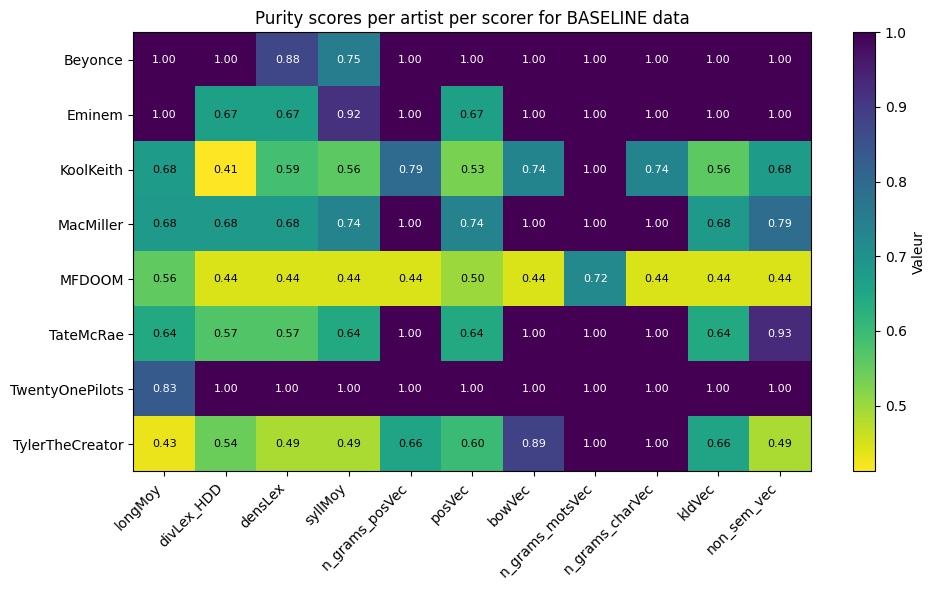

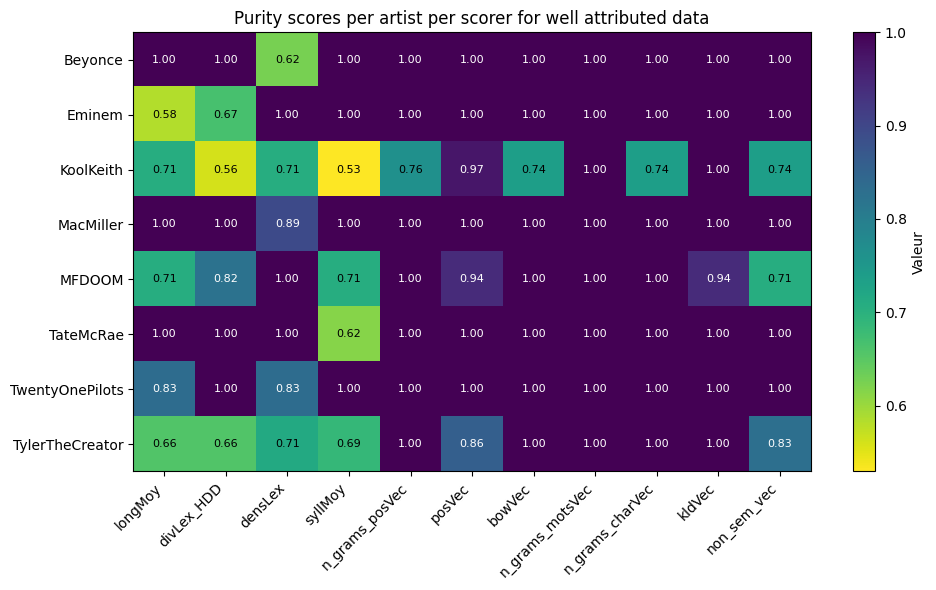

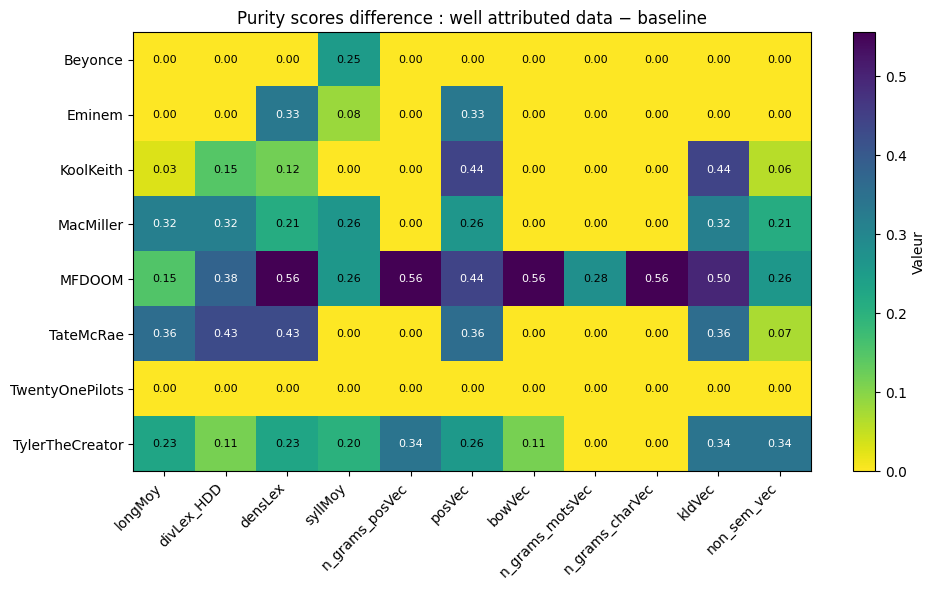

In [14]:
X = np.clip(np.array([[score_base[a][u] for u in score_base[a]] for a in score_base]), 0, 1)
xlabels = list(score_base[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes  # 8 labels en ordonnée
heatmap(X, xlabels=xlabels, ylabels=ylabels, title=f"{its_name} scores per artist per scorer for BASELINE data", cbar_label="Valeur")
plt.savefig(f"Baseline_{its_name}")

X = np.clip(np.array([[score_res[a][u] for u in score_res[a]] for a in score_res]), 0, 1)
xlabels = list(score_res[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes # 8 labels en ordonnée
heatmap(X, xlabels=xlabels, ylabels=ylabels, title=f"{its_name} scores per artist per scorer for well attributed data", cbar_label="Valeur")
plt.savefig(f"Normal_{its_name}")


X = np.clip(np.array([[score_res[a][u] - score_base[a][u] for u in score_base[a]] for a in score_res]), 0, 1)
xlabels = list(score_base[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes  # 8 labels en ordonnée
heatmap(X, xlabels=xlabels, ylabels=ylabels, title=f"{its_name} scores difference : well attributed data − baseline", cbar_label="Valeur")
plt.savefig(f"Difference_{its_name}")
